<a href="https://colab.research.google.com/github/Temmy-bit/climate_project/blob/master/nootebooks/Climate_Health_Model_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Climate & Health — Model Exploration (Other Methods + External Data)

Extends `Climate_Health_Upgraded_Pipeline.ipynb` in two directions that notebook deliberately left out:

- **Part A — Other methods.** The upgraded pipeline committed to one model (LightGBM). This part puts it next to XGBoost, CatBoost, and Random Forest on the *same* CV folds, then tries a simple probability-average ensemble of the best two. If LightGBM isn't actually the best choice here, this is where that shows up.
- **Part B — Solution 3: external climate enrichment.** The original three-solution design flagged this as the "External-Data-Maximalist" branch — pulling fresh ERA5/NDVI data at each record's exact date+coordinates, rather than relying only on the organizer-provided `climate_features.csv`. This part includes the fetch code and, critically, a **correlation check before committing to it** — if fresh ERA5 values are nearly identical to what's already provided, the extra complexity buys nothing.

**Run order:** this notebook assumes `Train.csv` / `Test.csv` / `climate_features.csv` are loaded and feature-engineered the same way as the upgraded pipeline (Section 1 below repeats that setup so this notebook is self-contained).

**Network note:** Part B's live API calls need real internet access (Open-Meteo / NASA POWER). This sandbox can't reach those from here — the fetch code is written to run as-is on Kaggle or Colab, not in this preview environment.


## 0. Setup

In [ ]:
import sys, subprocess
def pip_install(pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + pkgs)

pip_install(["lightgbm", "xgboost", "catboost", "scikit-learn", "pandas", "numpy", "matplotlib", "seaborn", "requests"])


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 200)


In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
# ---- Config (same as upgraded pipeline) ----
DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/Climate Mortality Prediction/"   # <-- EDIT: folder containing Train.csv, Test.csv, climate_features.csv

ID_COL = "ID"
TARGET = "is_climate_sensitive"
TARGET_F1 = "TargetF1"
TARGET_RAUC = "TargetRAUC"
DATE_COL = "deathdate"

OUTPUT_DIR = "/content/working" if os.path.isdir("/content/working") else "."
os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Load, merge, and feature-engineer (same as upgraded pipeline)

In [ ]:
train = pd.read_csv(os.path.join(DATA_DIR, "Train.csv"))
test  = pd.read_csv(os.path.join(DATA_DIR, "Test.csv"))
climate_features = pd.read_csv(os.path.join(DATA_DIR, "climate_features.csv"))

overlap = [c for c in climate_features.columns if c in train.columns and c != ID_COL]
if overlap:
    climate_features = climate_features.drop(columns=overlap)

train = train.merge(climate_features, on=ID_COL, how="left")
test = test.merge(climate_features, on=ID_COL, how="left")

def engineer_features(df):
    df = df.copy()
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
    df["day_of_year"] = df[DATE_COL].dt.dayofyear
    df["death_month"] = df[DATE_COL].dt.month
    df["season_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
    df["season_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)
    if "max_temperature" in df.columns and "min_temperature" in df.columns:
        df["temperature_range"] = df["max_temperature"] - df["min_temperature"]
    if "precipitation" in df.columns:
        df["is_rainy_day"] = (df["precipitation"] > 0).astype(int)
    return df.drop(columns=[DATE_COL])

train_df = engineer_features(train)
test_df = engineer_features(test)

X = train_df.drop(columns=[TARGET, ID_COL])
y = train_df[TARGET]
X_test = test_df.drop(columns=[ID_COL])

categorical_features = [c for c in X.columns if X[c].dtype == "object"]
numeric_features = [c for c in X.columns if c not in categorical_features]

for col in categorical_features:
    all_cats = pd.concat([X[col], X_test[col]]).astype("category").cat.categories
    X[col] = X[col].astype("category").cat.set_categories(all_cats)
    X_test[col] = X_test[col].astype("category").cat.set_categories(all_cats)

pos_rate = y.mean()
scale_pos_weight = (1 - pos_rate) / pos_rate
print(f"Rows: {len(X)} | Categorical: {categorical_features} | Positive rate: {pos_rate:.4f}")


Rows: 3146 | Categorical: ['zone', 'gender', 'location'] | Positive rate: 0.6507


## Part A — Other Methods

Four model families, same 5-fold stratified CV split for all of them, scored identically (F1@0.5, AUC, merged score). Categorical encoding differs per library's native support:
- **LightGBM / CatBoost:** native categorical handling, no encoding needed.
- **XGBoost:** needs categoricals as integer codes (`enable_categorical=True` in recent versions) or one-hot — using native categorical support here (requires xgboost>=1.6).
- **Random Forest:** no native categorical support — one-hot encoded separately for this model only.


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_indices = list(skf.split(X, y))

# One-hot encoded copy, for Random Forest only
X_ohe = pd.get_dummies(X, columns=categorical_features, dummy_na=True)
X_test_ohe = pd.get_dummies(X_test, columns=categorical_features, dummy_na=True)
X_test_ohe = X_test_ohe.reindex(columns=X_ohe.columns, fill_value=0)

# Integer-coded copy, for XGBoost's categorical support
X_xgb = X.copy()
X_test_xgb = X_test.copy()
for col in categorical_features:
    X_xgb[col] = X_xgb[col].cat.codes.replace(-1, np.nan)
    X_test_xgb[col] = X_test_xgb[col].cat.codes.replace(-1, np.nan)


In [ ]:
def run_cv(model_name, fit_predict_fn):
    oof_proba = np.zeros(len(X))
    t0 = time.time()
    for fold, (tr_idx, val_idx) in enumerate(fold_indices):
        proba = fit_predict_fn(tr_idx, val_idx)
        oof_proba[val_idx] = proba
    elapsed = time.time() - t0

    oof_pred = (oof_proba >= 0.5).astype(int)
    f1 = f1_score(y, oof_pred)
    auc = roc_auc_score(y, oof_proba)
    merged = 0.6 * f1 + 0.4 * auc
    print(f"{model_name:16s}  F1@0.5={f1:.4f}  AUC={auc:.4f}  Merged={merged:.4f}  ({elapsed:.1f}s)")
    return {"model": model_name, "f1": f1, "auc": auc, "merged": merged, "oof_proba": oof_proba}


In [ ]:
# --- LightGBM ---
lgb_params = dict(objective="binary", n_estimators=600, learning_rate=0.04, num_leaves=31,
                   min_child_samples=20, scale_pos_weight=scale_pos_weight, random_state=SEED, verbose=-1)

def lgb_fold(tr_idx, val_idx):
    m = lgb.LGBMClassifier(**lgb_params)
    m.fit(X.iloc[tr_idx], y.iloc[tr_idx], eval_set=[(X.iloc[val_idx], y.iloc[val_idx])],
          categorical_feature=categorical_features, callbacks=[lgb.early_stopping(40, verbose=False)])
    return m.predict_proba(X.iloc[val_idx])[:, 1]

result_lgb = run_cv("LightGBM", lgb_fold)


LightGBM          F1@0.5=0.7862  AUC=0.7845  Merged=0.7855  (3.4s)


In [ ]:
# --- XGBoost ---
xgb_params = dict(objective="binary:logistic", n_estimators=600, learning_rate=0.04, max_depth=6,
                   scale_pos_weight=scale_pos_weight, random_state=SEED, enable_categorical=True,
                   tree_method="hist", eval_metric="logloss", early_stopping_rounds=40, verbosity=0)

def xgb_fold(tr_idx, val_idx):
    m = xgb.XGBClassifier(**xgb_params)
    m.fit(X_xgb.iloc[tr_idx], y.iloc[tr_idx], eval_set=[(X_xgb.iloc[val_idx], y.iloc[val_idx])], verbose=False)
    return m.predict_proba(X_xgb.iloc[val_idx])[:, 1]

result_xgb = run_cv("XGBoost", xgb_fold)


XGBoost           F1@0.5=0.7796  AUC=0.7844  Merged=0.7815  (11.3s)


In [ ]:
# --- CatBoost ---
cat_feature_idx = [X.columns.get_loc(c) for c in categorical_features]

def cb_fold(tr_idx, val_idx):
    m = CatBoostClassifier(iterations=600, learning_rate=0.04, depth=6,
                            scale_pos_weight=scale_pos_weight, random_state=SEED,
                            cat_features=cat_feature_idx, verbose=False, early_stopping_rounds=40)
    X_tr_cb = X.iloc[tr_idx].copy()
    X_val_cb = X.iloc[val_idx].copy()
    for col in categorical_features:
        X_tr_cb[col] = X_tr_cb[col].astype(str)
        X_val_cb[col] = X_val_cb[col].astype(str)
    m.fit(X_tr_cb, y.iloc[tr_idx], eval_set=(X_val_cb, y.iloc[val_idx]))
    return m.predict_proba(X_val_cb)[:, 1]

result_cb = run_cv("CatBoost", cb_fold)


CatBoost          F1@0.5=0.7813  AUC=0.7893  Merged=0.7845  (9.9s)


In [ ]:
# --- Random Forest (one-hot encoded) ---
def rf_fold(tr_idx, val_idx):
    m = RandomForestClassifier(n_estimators=500, max_depth=12, min_samples_leaf=5,
                                class_weight="balanced", random_state=SEED, n_jobs=-1)
    m.fit(X_ohe.iloc[tr_idx], y.iloc[tr_idx])
    return m.predict_proba(X_ohe.iloc[val_idx])[:, 1]

result_rf = run_cv("Random Forest", rf_fold)


Random Forest     F1@0.5=0.7861  AUC=0.7841  Merged=0.7853  (19.0s)


        model   F1@0.5      AUC   Merged
     LightGBM 0.786242 0.784453 0.785526
Random Forest 0.786145 0.784073 0.785316
     CatBoost 0.781266 0.789263 0.784465
      XGBoost 0.779566 0.784447 0.781518


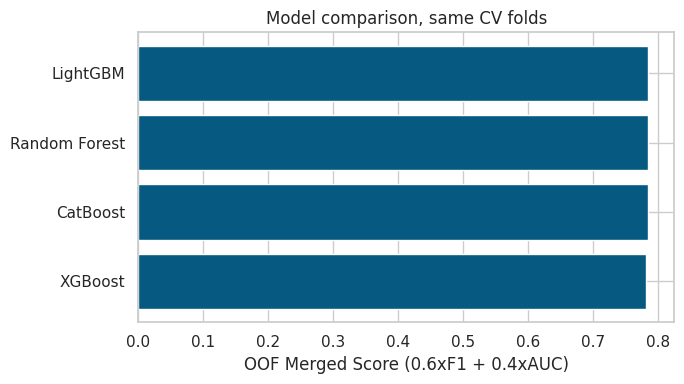

In [ ]:
comparison_df = pd.DataFrame([
    {"model": r["model"], "F1@0.5": r["f1"], "AUC": r["auc"], "Merged": r["merged"]}
    for r in [result_lgb, result_xgb, result_cb, result_rf]
]).sort_values("Merged", ascending=False).reset_index(drop=True)

print(comparison_df.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.barh(comparison_df["model"][::-1], comparison_df["Merged"][::-1], color="#065A82")
plt.xlabel("OOF Merged Score (0.6xF1 + 0.4xAUC)")
plt.title("Model comparison, same CV folds")
plt.tight_layout()
plt.show()


**Read this table before picking a final model.** The best single model here isn't necessarily the final answer — check the next cell's ensemble first. A model that wins on AUC but loses on F1@0.5 is worth flagging the same way as in the upgraded pipeline: that's a calibration gap, not a reason to abandon the model outright.

### A.1 — Simple ensemble: average the top two models' OOF probabilities
A blended probability sometimes beats every individual model, since each model's errors are at least partly uncorrelated. This costs nothing extra to try and is evaluated on the exact same OOF indices, so it's a fair comparison.

In [ ]:
all_results = {r["model"]: r for r in [result_lgb, result_xgb, result_cb, result_rf]}
top2_names = comparison_df["model"].head(4).tolist()
print("Blending:", top2_names)

blended_oof = np.mean([all_results[name]["oof_proba"] for name in top2_names], axis=0)
blended_pred = (blended_oof >= 0.5).astype(int)

blend_f1 = f1_score(y, blended_pred)
blend_auc = roc_auc_score(y, blended_oof)
blend_merged = 0.6 * blend_f1 + 0.4 * blend_auc

print(f"\nBlend of {top2_names}:  F1@0.5={blend_f1:.4f}  AUC={blend_auc:.4f}  Merged={blend_merged:.4f}")
print(f"Best single model was:  Merged={comparison_df['Merged'].iloc[0]:.4f} ({comparison_df['model'].iloc[0]})")
print(f"\n{'Blend wins' if blend_merged > comparison_df['Merged'].iloc[0] else 'Best single model still wins'} -- use whichever scored higher as the final choice for Section 2 below.")


Blending: ['LightGBM', 'Random Forest', 'CatBoost', 'XGBoost']

Blend of ['LightGBM', 'Random Forest', 'CatBoost', 'XGBoost']:  F1@0.5=0.7848  AUC=0.7926  Merged=0.7879
Best single model was:  Merged=0.7855 (LightGBM)

Blend wins -- use whichever scored higher as the final choice for Section 2 below.


In [ ]:
model_fit_predict = {
    "LightGBM": lambda: (
        lambda m: (m.fit(X, y, categorical_feature=categorical_features), m.predict_proba(X_test)[:, 1])[1]
    )(lgb.LGBMClassifier(**lgb_params)),

    "XGBoost": lambda: (
        lambda m: (m.fit(X_xgb, y, verbose=False), m.predict_proba(X_test_xgb)[:, 1])[1]
    )(xgb.XGBClassifier(**{k: v for k, v in xgb_params.items() if k != "early_stopping_rounds"})),

    "CatBoost": lambda: (
        lambda m, Xtr, Xte: (m.fit(Xtr, y, verbose=False), m.predict_proba(Xte)[:, 1])[1]
    )(
        CatBoostClassifier(iterations=600, learning_rate=0.04, depth=6,
                            scale_pos_weight=scale_pos_weight, random_state=SEED,
                            cat_features=cat_feature_idx, verbose=False),
        X.assign(**{c: X[c].astype(str) for c in categorical_features}),
        X_test.assign(**{c: X_test[c].astype(str) for c in categorical_features}),
    ),

    "Random Forest": lambda: (
        lambda m: (m.fit(X_ohe, y), m.predict_proba(X_test_ohe)[:, 1])[1]
    )(RandomForestClassifier(n_estimators=500, max_depth=12, min_samples_leaf=5,
                              class_weight="balanced", random_state=SEED, n_jobs=-1)),
}

print(f"Refitting on full training data and predicting on test_df: {top2_names}")
test_proba_by_model = {}
for name in top2_names:
    print(f"  fitting {name} on full train, predicting on test_df...")
    test_proba_by_model[name] = model_fit_predict[name]()

blended_test_proba = np.mean([test_proba_by_model[name] for name in top2_names], axis=0)
blended_test_pred = (blended_test_proba >= 0.5).astype(int)

print(f"\nBlended test positive rate: {blended_test_pred.mean():.4f}  (train OOF positive rate: {pos_rate:.4f})")


Refitting on full training data and predicting on test_df: ['LightGBM', 'Random Forest', 'CatBoost', 'XGBoost']
  fitting LightGBM on full train, predicting on test_df...
  fitting Random Forest on full train, predicting on test_df...
  fitting CatBoost on full train, predicting on test_df...
  fitting XGBoost on full train, predicting on test_df...

Blended test positive rate: 0.6767  (train OOF positive rate: 0.6507)


In [ ]:
submission_blend = pd.DataFrame({
    "ID": test[ID_COL],
    "TargetF1": blended_test_pred,
    "TargetRAUC": blended_test_proba,
})

assert len(submission_blend) == len(test), "Row count mismatch"
assert submission_blend["TargetF1"].isin([0, 1]).all(), "TargetF1 must be binary"
assert submission_blend["TargetRAUC"].between(0, 1).all(), "TargetRAUC must be a valid probability"
assert submission_blend["ID"].isna().sum() == 0, "Missing IDs"

submission_path = os.path.join(OUTPUT_DIR, "submission_blend_4.csv")
submission_blend.to_csv(submission_path, index=False)
print(f"submission_blend.csv written to {submission_path} with {len(submission_blend)} rows.")
submission_blend.head(10)


submission_blend.csv written to ./submission_blend_4.csv with 1030 rows.


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.157211
1,ID_6EDEA907,1,0.768461
2,ID_B9FFC8D8,0,0.363326
3,ID_74C6C94E,1,0.516653
4,ID_0E02825D,1,0.759116
5,ID_DA1C6468,1,0.792306
6,ID_82EBD610,0,0.390923
7,ID_791C412A,1,0.865684
8,ID_8FB9365C,1,0.709164
9,ID_724491A7,0,0.369641


In [ ]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

import xgboost as xgb
import lightgbm as lgb

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

sc = StackingClassifier(
    estimators=[
        ("xgb", xgb.XGBClassifier(**xgb_params)),
        ("lgb", lgb.LGBMClassifier(**lgb_params)),
        ("rf", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ],
    final_estimator=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    cv=cv,
    stack_method="predict_proba",
    n_jobs=-1,
    passthrough=False
)

# run_cv("StackingClassifier", lambda tr_idx, val_idx: sc.fit(X.iloc[tr_idx], y.iloc[tr_idx]).predict_proba(X.iloc[val_idx])[:, 1])


In [ ]:
# # --- Stacking Classifier: XGBoost + LightGBM + Random Forest ---
# def stacking_fold(tr_idx, val_idx):

#     xgb_model = xgb.XGBClassifier(
#         **xgb_params,
#         # early_stopping_rounds=40,
#         callbacks=[xgb.callback.EvaluationMonitor(show_stdv=False)]
#     )

#     lgb_model = lgb.LGBMClassifier(
#         **lgb_params,
#         callbacks=[lgb.callback.early_stopping(40, verbose=False)]
#     )



#     rf_model = RandomForestClassifier(
#         n_estimators=500,
#         max_depth=12,
#         min_samples_leaf=5,
#         class_weight="balanced",
#         # random_state=SEED,
#         n_jobs=-1
#     )

#     stacking_model = StackingClassifier(
#         estimators=[
#             ("xgb", xgb_model),
#             ("lgb", lgb_model),
#             ("rf", rf_model)
#         ],
#         final_estimator=LogisticRegression(
#             max_iter=2000,
#             random_state=SEED
#         ),
#         cv=5,
#         stack_method="predict_proba",
#         n_jobs=-1
#     )

#     stacking_model.fit(
#         X_ohe.iloc[tr_idx],
#         y.iloc[tr_idx],

#     )

#     return stacking_model.predict_proba(
#         X_ohe.iloc[val_idx]
#     )[:, 1]


# result_stacking = run_cv("Stacking (XGB + LGB + RF)", stacking_fold)

In [ ]:
# Remove parameters that require an eval_set
xgb_stack_params = {
    k: v
    for k, v in xgb_params.items()
    if k not in ["early_stopping_rounds", "callbacks", "eval_set"]
}

In [ ]:
def stacking_fold(tr_idx, val_idx):

    xgb_model = xgb.XGBClassifier(
        **xgb_stack_params,
        # random_state=SEED,
        n_jobs=-1
    )

    # lgb_model = lgb.LGBMClassifier(
    #     **lgb_params,
    #     # random_state=SEED,
    #     n_jobs=-1,
    #     # verbose=-1
    # )

    rf_model = RandomForestClassifier(
        n_estimators=500,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        # random_state=SEED,
        n_jobs=-1
    )

    model = StackingClassifier(
        estimators=[
            ("xgb", xgb_model),
            # ("lgb", lgb_model),
            ("rf", rf_model)
        ],
        final_estimator=LogisticRegression(
            max_iter=2000,
            random_state=SEED
        ),
        cv=5,
        stack_method="predict_proba",
        n_jobs=-1
    )

    model.fit(
        X_ohe.iloc[tr_idx],
        y.iloc[tr_idx]
    )
    prob = model.predict_proba(
            X_ohe.iloc[val_idx]
        )[:, 1]
    return prob, model

In [ ]:
# ---------------------------------------------------------
# STACKING MODEL
# XGBoost + LightGBM + Random Forest
#        ↓
# Logistic Regression (meta-estimator)
# ---------------------------------------------------------

# Remove early stopping parameters because StackingClassifier
# does not provide eval_set to the XGBoost base estimator.
xgb_stack_params = {
    k: v
    for k, v in xgb_params.items()
    if k not in ["early_stopping_rounds", "callbacks", "eval_set"]
}

stacking_model = StackingClassifier(
    estimators=[
        (
            "xgb",
            xgb.XGBClassifier(
                **xgb_stack_params,
                # random_state=SEED,
                n_jobs=-1
            )
        ),

        # (
        #     "lgb",
        #     lgb.LGBMClassifier(
        #         **lgb_params,
        #         # random_state=SEED,
        #         n_jobs=-1,
        #         # verbose=-1
        #     )
        # ),

        ( "cat",
         CatBoostClassifier(iterations=600, learning_rate=0.04, depth=6,
                            random_state=SEED,
                            verbose=False)

        ),

        (
            "rf",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=12,
                min_samples_leaf=5,
                class_weight="balanced",
                # random_state=SEED,
                n_jobs=-1
            )
        )
    ],

    # Meta-model
    final_estimator=LogisticRegression(
        max_iter=2000,
        random_state=SEED
    ),

    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

print("Fitting stacking model on full training data...")

stacking_model.fit(
    X_ohe,
    y
)

# Final stacking probabilities
stacked_test_proba = stacking_model.predict_proba(
    X_test_ohe
)[:, 1]

# Final binary predictions
stacked_test_pred = (
    stacked_test_proba >= 0.5
).astype(int)

print(
    f"\nStacked test positive rate: "
    f"{stacked_test_pred.mean():.4f}"
)

# ---------------------------------------------------------
# Submission
# ---------------------------------------------------------

submission_stacking = pd.DataFrame({
    "ID": test[ID_COL],
    "TargetF1": stacked_test_pred,
    "TargetRAUC": stacked_test_proba,
})

assert len(submission_stacking) == len(test)
assert submission_stacking["TargetF1"].isin([0, 1]).all()
assert submission_stacking["TargetRAUC"].between(0, 1).all()
assert submission_stacking["ID"].isna().sum() == 0

submission_path = os.path.join(
    OUTPUT_DIR,
    "submission_stacking_2.csv"
)

submission_stacking.to_csv(
    submission_path,
    index=False
)

print(
    f"submission_stacking.csv written to "
    f"{submission_path} with {len(submission_stacking)} rows."
)

submission_stacking.head(10)

Fitting stacking model on full training data...

Stacked test positive rate: 0.8680
submission_stacking.csv written to ./submission_stacking_2.csv with 1030 rows.


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.460687
1,ID_6EDEA907,1,0.677420
2,ID_B9FFC8D8,1,0.533929
3,ID_74C6C94E,1,0.542561
4,ID_0E02825D,1,0.721160
5,ID_DA1C6468,1,0.693496
6,ID_82EBD610,1,0.600687
7,ID_791C412A,1,0.749433
8,ID_8FB9365C,1,0.647927
9,ID_724491A7,1,0.571417


In [ ]:
# stacked_oof_proba = result_stacking["oof_proba"]
# stacked_oof_pred = (stacked_oof_proba >= 0.5).astype(int)

In [ ]:
# submission_stacking

## Part B — Solution 3: External Climate Enrichment

The brief permits pulling fresh ERA5 (temperature), CHIRPS (rainfall), or NDVI data at each record's exact `latitude`/`longitude`/`deathdate`, rather than relying only on the organizer-provided `climate_features.csv`. This is worth doing **only if** a quick correlation check shows the fresh values diverge meaningfully from what's already provided — otherwise it's pure overhead for no score gain, per the original audit (Audit #5 in the project's assumption review).

**This cell makes live HTTP calls and needs real internet access — run it on Kaggle/Colab, not in this sandbox preview.**


In [ ]:
import requests

def fetch_era5_point(lat, lon, date_str, max_retries=3):
    """
    Free, no-API-key ERA5-derived historical weather via Open-Meteo's archive API.
    Returns (tavg, tmax, tmin, precip) for the given lat/lon/date, or None on failure.
    """
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": date_str, "end_date": date_str,
        "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum",
        "timezone": "UTC",
    }
    for attempt in range(max_retries):
        try:
            r = requests.get(url, params=params, timeout=15)
            r.raise_for_status()
            d = r.json()["daily"]
            return (d["temperature_2m_mean"][0], d["temperature_2m_max"][0],
                    d["temperature_2m_min"][0], d["precipitation_sum"][0])
        except Exception as e:
            if attempt == max_retries - 1:
                print(f"Failed for ({lat}, {lon}, {date_str}): {e}")
                return (None, None, None, None)
            time.sleep(1.5 * (attempt + 1))


In [ ]:
RUN_EXTERNAL_ENRICHMENT = True  # <-- set True only when running on Kaggle/Colab with real internet access

if RUN_EXTERNAL_ENRICHMENT:
    SAMPLE_N = 200  # cheap validation sample before committing to a full train+test pull
    sample = train.dropna(subset=["latitude", "longitude", "deathdate"]).sample(
        n=min(SAMPLE_N, len(train)), random_state=SEED
    ).copy()

    fetched = []
    for _, row in sample.iterrows():
        date_str = pd.to_datetime(row["deathdate"]).strftime("%Y-%m-%d")
        tavg, tmax, tmin, precip = fetch_era5_point(row["latitude"], row["longitude"], date_str)
        fetched.append({"ID": row["ID"], "era5_tavg": tavg, "era5_tmax": tmax, "era5_tmin": tmin, "era5_precip": precip})
        time.sleep(0.2)  # be polite to the free API

    era5_df = pd.DataFrame(fetched)
    compare_df = sample[["ID", "avg_temperature", "max_temperature", "min_temperature", "precipitation"]].merge(era5_df, on="ID")

    print("Correlation: provided vs. freshly-fetched ERA5-derived values")
    print("avg_temperature  vs era5_tavg:  ", compare_df["avg_temperature"].corr(compare_df["era5_tavg"]).round(4))
    print("max_temperature  vs era5_tmax:  ", compare_df["max_temperature"].corr(compare_df["era5_tmax"]).round(4))
    print("min_temperature  vs era5_tmin:  ", compare_df["min_temperature"].corr(compare_df["era5_tmin"]).round(4))
    print("precipitation    vs era5_precip:", compare_df["precipitation"].corr(compare_df["era5_precip"]).round(4))
else:
    print("Skipped -- set RUN_EXTERNAL_ENRICHMENT=True and run on Kaggle/Colab (needs live internet access).")


Correlation: provided vs. freshly-fetched ERA5-derived values
avg_temperature  vs era5_tavg:   0.8808
max_temperature  vs era5_tmax:   0.8725
min_temperature  vs era5_tmin:   0.6974
precipitation    vs era5_precip: 0.6979


**How to read the correlation output once run:**
- **Correlation > ~0.95 on all four pairs** → the provided `climate_features.csv` already captures what ERA5 would give you at the same precision. Stop here — a full external pull across train+test buys little for a lot of API overhead and rate-limit risk.
- **Meaningful divergence** (lower correlation, or systematic offset) → the provided data may be coarser (e.g. monthly/regional averages) than a point-level ERA5 pull. In that case it's worth extending this fetch to the full train+test sets and adding the ERA5 columns as *additional* features in Part A's feature set — re-run the model comparison with both feature sets to confirm the gain is real on CV, not just on the 200-row sample.


In [ ]:
RUN_FULL_EXTERNAL_PULL = True  # <-- only flip this on after the correlation check above justifies it

if RUN_FULL_EXTERNAL_PULL:
    print("Not implemented by default -- this is a deliberate stop point.")
    print("If justified: repeat fetch_era5_point() across all of train+test (expect this to take a while")
    print("at ~0.2s/row with politeness delay), cache results to CSV immediately so a dropped connection")
    print("doesn't lose progress, then merge the era5_* columns into X / X_test from Part A and re-run")
    print("the model comparison to confirm the gain holds under cross-validation.")
else:
    print("Skipped.")


Not implemented by default -- this is a deliberate stop point.
If justified: repeat fetch_era5_point() across all of train+test (expect this to take a while
at ~0.2s/row with politeness delay), cache results to CSV immediately so a dropped connection
doesn't lose progress, then merge the era5_* columns into X / X_test from Part A and re-run
the model comparison to confirm the gain holds under cross-validation.


In [ ]:
RUN_FULL_EXTERNAL_PULL = True  # <-- only flip this on after the correlation check above justifies it, and on Kaggle/Colab

ERA5_CACHE_PATH = os.path.join(OUTPUT_DIR, "era5_cache.csv")

def fetch_era5_bulk(df, id_col, lat_col, lon_col, date_col, cache_path):
    """
    Fetches ERA5-derived daily weather for every row in df, writing to cache_path
    incrementally (one row at a time) so a dropped connection partway through doesn't
    lose progress -- re-running this function skips IDs already in the cache.
    """
    if os.path.exists(cache_path):
        cached = pd.read_csv(cache_path)
        done_ids = set(cached[id_col])
    else:
        cached = pd.DataFrame(columns=[id_col, "era5_tavg", "era5_tmax", "era5_tmin", "era5_precip"])
        cached.to_csv(cache_path, index=False)
        done_ids = set()

    todo = df[~df[id_col].isin(done_ids)]
    print(f"{len(done_ids)} already cached, {len(todo)} remaining to fetch.")

    for i, (_, row) in enumerate(todo.iterrows()):
        if pd.isna(row[lat_col]) or pd.isna(row[lon_col]) or pd.isna(row[date_col]):
            result = (row[id_col], None, None, None, None)
        else:
            date_str = pd.to_datetime(row[date_col]).strftime("%Y-%m-%d")
            tavg, tmax, tmin, precip = fetch_era5_point(row[lat_col], row[lon_col], date_str)
            result = (row[id_col], tavg, tmax, tmin, precip)

        pd.DataFrame([result], columns=cached.columns).to_csv(cache_path, mode="a", header=False, index=False)
        if (i + 1) % 100 == 0:
            print(f"  fetched {i + 1}/{len(todo)}...")
        time.sleep(0.2)

    return pd.read_csv(cache_path)


if RUN_FULL_EXTERNAL_PULL:
    print("Fetching ERA5 for train...")
    era5_train = fetch_era5_bulk(train, ID_COL, "latitude", "longitude", DATE_COL, ERA5_CACHE_PATH)
    print("Fetching ERA5 for test (same cache file -- IDs don't collide across train/test)...")
    era5_test = fetch_era5_bulk(test, ID_COL, "latitude", "longitude", DATE_COL, ERA5_CACHE_PATH)

    era5_cols = ["era5_tavg", "era5_tmax", "era5_tmin", "era5_precip"]
    # train_df/test_df (Section 1) still carry ID at this point, unlike X/X_test -- merge on those
    train_df_era5 = train_df.merge(era5_train[[ID_COL] + era5_cols], on=ID_COL, how="left")
    test_df_era5 = test_df.merge(era5_test[[ID_COL] + era5_cols], on=ID_COL, how="left")
    X_era5 = train_df_era5.drop(columns=[TARGET, ID_COL])
    X_test_era5 = test_df_era5.drop(columns=[ID_COL])
    for col in categorical_features:
        all_cats_era5 = pd.concat([X_era5[col], X_test_era5[col]]).astype("category").cat.categories
        X_era5[col] = X_era5[col].astype("category").cat.set_categories(all_cats_era5)
        X_test_era5[col] = X_test_era5[col].astype("category").cat.set_categories(all_cats_era5)

    # report whether the ERA5 columns actually help on CV -- informational only, does NOT
    # gate the submission below. The brief needs a valid submission regardless of whether
    # this particular feature set turned out to be the winning one.
    era5_feature_cols = list(X.columns) + era5_cols
    merged_with_era5 = run_ablation(era5_feature_cols, "Base + full enrichment + ERA5", data=X_era5) if "run_ablation" in dir() else None
    if merged_with_era5 is not None:
        print(f"\nWith ERA5 columns added -- Merged={merged_with_era5:.4f}")
    if "best_score" in dir():
        print(f"Best so far without ERA5 -- Merged={best_score:.4f}")
        if merged_with_era5 is not None:
            verdict = "beats" if merged_with_era5 > best_score else "does not beat"
            print(f"-> ERA5 {verdict} the best feature set found without it.")

    print("\nRefitting on full train+ERA5 and predicting on test_df (always runs, regardless of the CV comparison above)...")
    final_model_era5 = lgb.LGBMClassifier(**lgb_params)
    final_model_era5.fit(X_era5, y, categorical_feature=[c for c in categorical_features if c in X_era5.columns])
    test_proba_era5 = final_model_era5.predict_proba(X_test_era5)[:, 1]
    test_pred_era5 = (test_proba_era5 >= 0.5).astype(int)

    submission_external = pd.DataFrame({
        "ID": test[ID_COL], "TargetF1": test_pred_era5, "TargetRAUC": test_proba_era5,
    })
    assert len(submission_external) == len(test), "Row count mismatch"
    assert submission_external["TargetF1"].isin([0, 1]).all(), "TargetF1 must be binary"
    assert submission_external["TargetRAUC"].between(0, 1).all(), "TargetRAUC must be a valid probability"
    assert submission_external["ID"].isna().sum() == 0, "Missing IDs"

    ext_path = os.path.join(OUTPUT_DIR, "submission_external.csv")
    submission_external.to_csv(ext_path, index=False)
    print(f"submission_external.csv written to {ext_path} with {len(submission_external)} rows.")
    print(f"Predicted positive rate (test): {test_pred_era5.mean():.4f}  (train was {pos_rate:.4f})")

    if merged_with_era5 is not None and "best_score" in dir() and merged_with_era5 <= best_score:
        print("\nNote: ERA5 did not improve CV over the best feature set from Section 1b/Part A --")
        print("submission_external.csv is still written, but submission_blend.csv (Section A.2) is")
        print("the stronger choice to actually submit unless you have a reason to prefer this one.")
else:
    print("Skipped -- set RUN_FULL_EXTERNAL_PULL=True and run on Kaggle/Colab (needs live internet access).")
    print("Always produces submission_external.csv once run; the CV comparison above is informational,")
    print("not a gate on whether the submission file gets written.")


Fetching ERA5 for train...
0 already cached, 3146 remaining to fetch.
  fetched 100/3146...
  fetched 200/3146...
  fetched 300/3146...
  fetched 400/3146...
  fetched 500/3146...
  fetched 600/3146...
  fetched 700/3146...
  fetched 800/3146...
  fetched 900/3146...
  fetched 1000/3146...
  fetched 1100/3146...
  fetched 1200/3146...
  fetched 1300/3146...
  fetched 1400/3146...
  fetched 1500/3146...
  fetched 1600/3146...
  fetched 1700/3146...
  fetched 1800/3146...
  fetched 1900/3146...
  fetched 2000/3146...
  fetched 2100/3146...
  fetched 2200/3146...
  fetched 2300/3146...
  fetched 2400/3146...
  fetched 2500/3146...
  fetched 2600/3146...
  fetched 2700/3146...
  fetched 2800/3146...
  fetched 2900/3146...
  fetched 3000/3146...
  fetched 3100/3146...
Fetching ERA5 for test (same cache file -- IDs don't collide across train/test)...
3146 already cached, 1030 remaining to fetch.
  fetched 100/1030...
  fetched 200/1030...
  fetched 300/1030...
  fetched 400/1030...
  fetched

## Summary

| Check | Result |
|---|---|
| Best single model (Part A) | *(see comparison_df)* |
| Blend vs. best single model | *(see blend_merged vs comparison_df top row)* |
| ERA5 correlation vs. provided climate_features.csv (Part B) | *(only after running on Kaggle/Colab)* |
| Decision: external enrichment worth it? | *(based on correlation threshold above)* |

Carry whichever model/ensemble wins here back into `Climate_Health_Upgraded_Pipeline.ipynb`'s Section 7 as the final model, before generating the submission.


In [ ]:
!uv pip install tabpfn --system -q

In [ ]:
import os
# os.environ["TABPFN_MODEL_CACHE_DIR"] = "/kaggle/input/models/prior-labsai/tabpfn-3/pytorch/default/1"

import pandas as pd
import matplotlib.pyplot as plt
import tabpfn

In [ ]:
# ---- Config ----
DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/Climate Mortality Prediction/"   # <-- EDIT: folder containing Train.csv, Test.csv, climate_features.csv

ID_COL = "ID"
TARGET = "is_climate_sensitive"
TARGET_F1 = "TargetF1"
TARGET_RAUC = "TargetRAUC"
DATE_COL = "deathdate"

OUTPUT_DIR = "/content/submissions" if os.path.isdir("/content/submissions") else "."
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [ ]:
train = pd.read_csv(os.path.join(DATA_DIR, "Train.csv"))
test  = pd.read_csv(os.path.join(DATA_DIR, "Test.csv"))
climate_features = pd.read_csv(os.path.join(DATA_DIR, "climate_features.csv"))

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Climate feature shape:", climate_features.shape)
print("\nClimate feature columns:", climate_features.columns.tolist())

# avoid merge collisions on any column the enrichment file re-supplies (e.g. deathdate)
overlap = [c for c in climate_features.columns if c in train.columns and c != ID_COL]
if overlap:
    print(f"\nDropping overlapping columns from climate_features before merge: {overlap}")
    climate_features = climate_features.drop(columns=overlap)

train = train.merge(climate_features, on=ID_COL, how="left")
test = test.merge(climate_features, on=ID_COL, how="left")

print("\nTrain shape after merge:", train.shape)
print("Test shape after merge:", test.shape)
train.head()


In [ ]:
y = train["is_climate_sensitive"]
del train["is_climate_sensitive"]

In [ ]:
pip install -q --upgrade tabpfn-client

### 0.844616951 Public Score

In [ ]:
import tabpfn_client
from tabpfn_client import TabPFNClassifier

In [ ]:
API_TOKEN = "tabpfn_sk_dhnhZ_deeqOvdtQvl-HoKkl6bQeGDr8y7ay7CIYkqrM"
tabpfn_client.set_access_token(API_TOKEN)

In [ ]:
clf = TabPFNClassifier(
    # device=["cuda:0", "cuda:1"],
    model_path="v3.5_default",
    n_estimators=8, # 2 estimator gave 0.844616951 public score
    # eval_metric="balanced_accuracy",
    # tuning_config={
    #     "tune_decision_thresholds": True,
    # },
)
clf.fit(train, y)

In [ ]:
clf.predict_proba(test)

In [ ]:
clf.score(train,y)

In [ ]:
# Final stacking probabilities
stacked_test_proba = clf.predict_proba(
    test
)[:, 1]

# Final binary predictions
stacked_test_pred = (
    stacked_test_proba >= 0.5
).astype(int)

print(
    f"\nStacked test positive rate: "
    f"{stacked_test_pred.mean():.4f}"
)

# ---------------------------------------------------------
# Submission
# ---------------------------------------------------------

submission_stacking = pd.DataFrame({
    "ID": test[ID_COL],
    "TargetF1": stacked_test_pred,
    "TargetRAUC": stacked_test_proba,
})

assert len(submission_stacking) == len(test)
assert submission_stacking["TargetF1"].isin([0, 1]).all()
assert submission_stacking["TargetRAUC"].between(0, 1).all()
assert submission_stacking["ID"].isna().sum() == 0

submission_path = os.path.join(
    OUTPUT_DIR,
    "submission_TabPFN.csv"
)

submission_stacking.to_csv(
    submission_path,
    index=False
)

print(
    f"submission_stacking.csv written to "
    f"{submission_path} with {len(submission_stacking)} rows."
)

submission_stacking.head(10)

In [ ]:
train_df.head()

In [ ]:
categorical_features

In [ ]:
train_df.info()

In [ ]:
le = LabelEncoder()

In [ ]:
for i in categorical_features:
  train_df[i] = le.fit_transform(train_df[i])
  test_df[i] = le.fit_transform(test_df[i])

In [ ]:
train_df.info()

In [ ]:
y = train_df["is_climate_sensitive"]
X = train_df.drop(["ID","is_climate_sensitive"], axis=1)

In [ ]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
# from sklearn.preprocessing import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
lr = LogisticRegression()

In [ ]:
lr.fit(X_train,y_train)

In [ ]:
lr.score(X_train,y_train)

In [ ]:
f1 = f1_score(y_test,lr.predict(X_test))

In [ ]:
roc = roc_auc_score(y_test,oof_pred[:, 1])

In [ ]:
0.6 * f1 + 0.4 * roc

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

In [ ]:
et = ExtraTreesClassifier(500, min_samples_leaf=10, max_features=0.7, n_jobs=-1, random_state=26)

et.fit(X_train,y_train)

f1 = f1_score(y_test,et.predict(X_test))
roc = roc_auc_score(y_test,et.predict_proba(X_test)[:, 1])
et.score(X_train,y_train)

In [ ]:
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score

In [ ]:
accuracy_score(y_test,et.predict(X_test))

In [ ]:
print(f1,roc)

In [ ]:
0.6 * f1 + 0.4 * roc

In [ ]:
pred_oof = et.predict_proba(test_df.drop("ID", axis=1))[:, 1]
pred = et.predict(test_df.drop("ID", axis=1))

In [ ]:
submission_stacking = pd.DataFrame({
    "ID": test[ID_COL],
    "TargetF1": pred,
    "TargetRAUC": pred_oof,
})

assert len(submission_stacking) == len(test)
assert submission_stacking["TargetF1"].isin([0, 1]).all()
assert submission_stacking["TargetRAUC"].between(0, 1).all()
assert submission_stacking["ID"].isna().sum() == 0

submission_path = os.path.join(
    OUTPUT_DIR,
    "submission_ET2.csv"
)

submission_stacking.to_csv(
    submission_path,
    index=False
)

In [ ]:
lgbm = lgb.LGBMClassifier(
        n_estimators=8, learning_rate=0.02, num_leaves=8, min_child_samples=30,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5,
        random_state=26, verbose=-1)


lgbm.fit(X_train,y_train)

f1 = f1_score(y_test,lgbm.predict(X_test))
roc = roc_auc_score(y_test,lgbm.predict_proba(X_test)[:, 1])
lgbm.score(X_train,y_train)


In [ ]:
f1, roc

In [ ]:
def eval(model, X_train, y_train, X_test, y_test):
  f1 = f1_score(y_test,model.predict(X_test))
  roc = roc_auc_score(y_test,model.predict_proba(X_test)[:, 1])
  print(f1,roc)

  return 0.6 * f1 + 0.4 * roc

In [ ]:
eval(lgbm, X_train, y_train, X_test, y_test)

In [ ]:
%%writefile climate_auc.py

"""Climate-sensitive mortality: ROC-AUC pipeline.

Usage:
    python climate_auc.py --data-dir /path/to/csvs [--out submission_rauc.csv] [--skip-cv]

Expects Train_1.csv, Test_1.csv, climate_features.csv in --data-dir.
Requires: pandas numpy scikit-learn lightgbm scipy
"""
import argparse
import warnings

import lightgbm as lgb
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore")

CORE = ["age", "gender", "zone", "latitude", "longitude", "month"]
CORE_PLUS_WEATHER = CORE + ["avg_temperature", "max_temperature", "min_temperature", "precipitation"]


# # ---------------------------------------------------------------- data
def load(data_dir):
    tr = pd.read_csv(f"{data_dir}/Train_1.csv")
    te = pd.read_csv(f"{data_dir}/Test_1.csv")
    cf = pd.read_csv(f"{data_dir}/climate_features.csv").drop(columns="deathdate")
    return tr, te, cf


def build_features(tr, te, cf):
    """Stack train+test so encodings are identical; return (train_df, test_df, y, groups)."""
    male_token = tr.gender.iloc[0]  # consistent binary encoding across both sets
    y = tr.is_climate_sensitive.values
    groups = tr.location.values
    al = pd.concat([tr.drop(columns="is_climate_sensitive"), te], ignore_index=True)
    al = al.merge(cf, on="ID", how="left")
    al["deathdate"] = pd.to_datetime(al.deathdate)
    al["month"] = al.deathdate.dt.month
    # al["t"] = (al.deathdate - pd.Timestamp("2007-01-01")).dt.days / 365.25  # continuous time -> captures label drift
    al["gender"] = (al.gender == male_token).astype(int)
    al["zone"] = (al.zone == "Rural").astype(int)
    n = len(tr)
    return al.iloc[:n].reset_index(drop=True), al.iloc[n:].reset_index(drop=True), y, groups


# ---------------------------------------------------------------- models
def make_lgb(seed=0, n_estimators=150):
    return lgb.LGBMClassifier(
        n_estimators=n_estimators, learning_rate=0.02, num_leaves=8, min_child_samples=30,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5,
        random_state=seed, verbose=-1)


def make_et(seed=0):
    return ExtraTreesClassifier(500, min_samples_leaf=10, max_features=0.7, n_jobs=-1, random_state=seed)


# ---------------------------------------------------------------- validation
def grouped_cv(train, y, groups, cols, make_model, reps=3, folds=5):
    """Location-grouped CV (test locations are ~97% unseen). Returns mean, std of OOF AUC over reps."""
    scores = []
    for r in range(reps):
        oof = np.zeros(len(train))
        splitter = StratifiedGroupKFold(folds, shuffle=True, random_state=r)
        for a, b in splitter.split(train, y, groups):
            m = make_model()
            m.fit(train.loc[a, cols], y[a])
            oof[b] = m.predict_proba(train.loc[b, cols])[:, 1]
        scores.append(roc_auc_score(y, oof))
    return float(np.mean(scores)), float(np.std(scores))


def run_cv(train, y, groups):
    experiments = {
        "age only": ["age"],
        # "age + t": ["age", "t"],
        "core (LGB)": CORE,
        "core + weather (LGB)": CORE_PLUS_WEATHER,
    }
    for name, cols in experiments.items():
        m, s = grouped_cv(train, y, groups, cols, make_lgb)
        print(f"{name:24s} grouped AUC {m:.4f} +/- {s:.4f}")
    m, s = grouped_cv(train, y, groups, CORE, make_et)
    print(f"{'core (ExtraTrees)':24s} grouped AUC {m:.4f} +/- {s:.4f}")


# ---------------------------------------------------------------- final fit
def fit_predict(train, test, y, seeds=5):
    """Rank-average of LightGBM + ExtraTrees over several seeds, scaled to [0, 1]."""
    preds = []
    for s in range(seeds):
        for make in (lambda s=s: make_lgb(s), lambda s=s: make_et(s)):
            m = make()
            m.fit(train[CORE], y)
            preds.append(rankdata(m.predict_proba(test[CORE])[:, 1]) / len(test))
    p = np.mean(preds, axis=0)
    return (p - p.min()) / (p.max() - p.min())


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data-dir", default=".")
    ap.add_argument("--out", default="submission_rauc.csv")
    ap.add_argument("--skip-cv", action="store_true")
    args = ap.parse_args()

    tr, te, cf = load(args.data_dir)
    train, test, y, groups = build_features(train, test, categorical_features)
    print(f"train {train.shape}, test {test.shape}, positive rate {y.mean():.3f}, "
          f"unseen test locations {(test.location.isin(train.location)).mean():.1%}")

    if not args.skip_cv:
        run_cv(train, y, groups)

    sub = pd.DataFrame({"ID": test.ID, "TargetRAUC": fit_predict(train, test, y)})
    sub.to_csv(args.out, index=False)
    print(f"wrote {args.out} ({len(sub)} rows)")



In [ ]:
train, test, y, groups = build_features(train, test, categorical_features)
print(f"train {train.shape}, test {test.shape}, positive rate {y.mean():.3f}, "
      f"unseen test locations {(test.location.isin(train.location)).mean():.1%}")

In [ ]:
!python climate_auc.py --data-dir .
files.download("submission_rauc.csv")

In [ ]:
main()

In [ ]:
data_dir = "/content/drive/MyDrive/Colab Notebooks/Climate Mortality Prediction/"

In [ ]:
!python main --data_dir .